# RenYou AI Skin Assistant — Exploration, Experimentation and Evaluation

This notebook gathers the visualizations used for **Chapter 3** of the internship report
(*Implementation, Experimentation and Evaluation of the Solution*):

1. Data exploration and cleaning (missing values, `ingredients` field)
2. Dermatological Knowledge Graph (synergies / interactions between active ingredients)
3. Recommendation engine evaluation (Precision@3 / Precision@5)
4. Chatbot evaluation — intent classifier (Accuracy / Macro-F1)
5. Summary of metrics against targets

**Files to upload** (in the cell below) — exactly those from the GitHub repo:

- `parafendri_products_raw.csv`
- `parafendri_products_clean.csv`
- `knowledge_graph.py`
- `safety_rules.py`
- `recommender.py`
- `tfidf_vectorizer.joblib`
- `product_matrix.joblib`
- `products_metadata.joblib`
- `chatbot_dataset.csv`


## 0. Setup


In [2]:
import os, sys, ast, re, unicodedata, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

REQUIRED_FILES = [
    "parafendri_products_raw.csv",
    "parafendri_products_clean.csv",
    "knowledge_graph.py",
    "safety_rules.py",
    "recommender.py",
    "tfidf_vectorizer.joblib",
    "product_matrix.joblib",
    "products_metadata.joblib",
    "chatbot_dataset.csv",
]

missing = [f for f in REQUIRED_FILES if not os.path.exists(f)]

if missing:
    try:
        from google.colab import files
        print("Missing files:", missing)
        print("-> Select them all in the dialog box below.")
        uploaded = files.upload()
    except ImportError:
        raise FileNotFoundError(
            f"Missing files and not running in Colab: {missing}"
        )

still_missing = [f for f in REQUIRED_FILES if not os.path.exists(f)]
assert not still_missing, f"Still missing: {still_missing}"
print("All required files are present.")


All required files are present.


In [3]:
# Rebuild the directory tree expected by recommender.py
# (src/recommendation/*.py + models/recommendation/*.joblib), identical to the repo.

os.makedirs("src/recommendation", exist_ok=True)
os.makedirs("models/recommendation", exist_ok=True)

open("src/__init__.py", "w").close()
open("src/recommendation/__init__.py", "w").close()

for module in ["knowledge_graph.py", "safety_rules.py", "recommender.py"]:
    target = f"src/recommendation/{module}"
    if not os.path.exists(target):
        os.replace(module, target) if os.path.exists(module) else None

for artefact in ["tfidf_vectorizer.joblib", "product_matrix.joblib", "products_metadata.joblib"]:
    target = f"models/recommendation/{artefact}"
    if not os.path.exists(target):
        os.replace(artefact, target) if os.path.exists(artefact) else None

sys.path.insert(0, os.getcwd())
print("Directory tree ready.")


Directory tree ready.


## 1. Data Exploration and Cleaning

Reproduces the findings from section **3.3** of the report: missing values in the
raw dataset (296 products scraped from Parafendri) and the state of the `ingredients`
field, which is central to the recommendation engine.


In [4]:
raw = pd.read_csv("parafendri_products_raw.csv")
clean = pd.read_csv("parafendri_products_clean.csv")

print(f"Products (raw)     : {len(raw)}")
print(f"Products (cleaned) : {len(clean)}")


Products (raw)     : 296
Products (cleaned) : 296


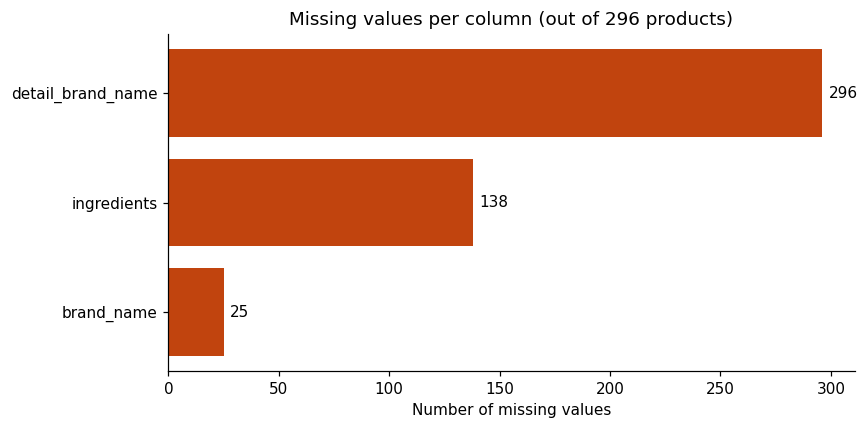

In [5]:
# --- Fig. 3.1 equivalent — Missing values per column (raw dataset) ---

missing = raw.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(missing.index, missing.values, color="#c1440e")
ax.set_xlabel("Number of missing values")
ax.set_title(f"Missing values per column (out of {len(raw)} products)")
for y, v in enumerate(missing.values):
    ax.text(v + 3, y, str(v), va="center")
ax.invert_yaxis()
plt.tight_layout()
plt.show()


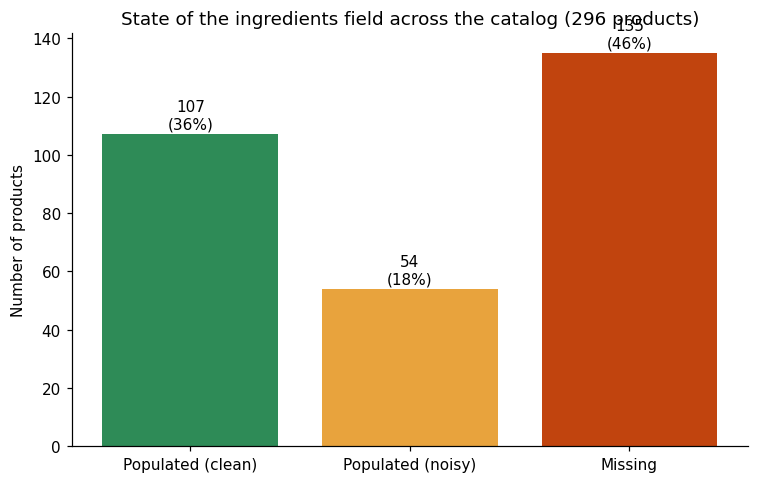

Products used by the engine (is_non_skincare=False): 264 / 296


In [6]:
# --- Fig. 3.2 equivalent — State of the ingredients field on the cleaned catalog ---
# clean   : ingredients populated AND at least one active ingredient detected
# noisy   : ingredients populated but no active ingredient recognized by the Knowledge Graph
# missing : no ingredient information retrieved

def parse_list(value):
    if pd.isna(value):
        return []
    try:
        result = ast.literal_eval(str(value))
        return result if isinstance(result, list) else []
    except (ValueError, SyntaxError):
        return []

active = clean["active_ingredients"].apply(parse_list)
has_data = clean["has_ingredients_data"].astype(bool)
has_active = active.apply(len).gt(0)

state_counts = pd.Series({
    "Populated (clean)": (has_data & has_active).sum(),
    "Populated (noisy)": (has_data & ~has_active).sum(),
    "Missing": (~has_data).sum(),
})

fig, ax = plt.subplots(figsize=(7, 4.5))
colors = ["#2e8b57", "#e8a33d", "#c1440e"]
bars = ax.bar(state_counts.index, state_counts.values, color=colors)
ax.set_ylabel("Number of products")
ax.set_title(f"State of the ingredients field across the catalog ({len(clean)} products)")
for bar, v in zip(bars, state_counts.values):
    pct = 100 * v / len(clean)
    ax.text(bar.get_x() + bar.get_width() / 2, v + 2, f"{v}\n({pct:.0f}%)", ha="center")
plt.tight_layout()
plt.show()

print(f"Products used by the engine (is_non_skincare=False): "
      f"{(~clean['is_non_skincare'].astype(bool)).sum()} / {len(clean)}")


## 2. Dermatological Knowledge Graph

Reproduces **Fig. 3.3**: synergy and interaction relationships between the 9 active
ingredients modeled in `knowledge_graph.py`.


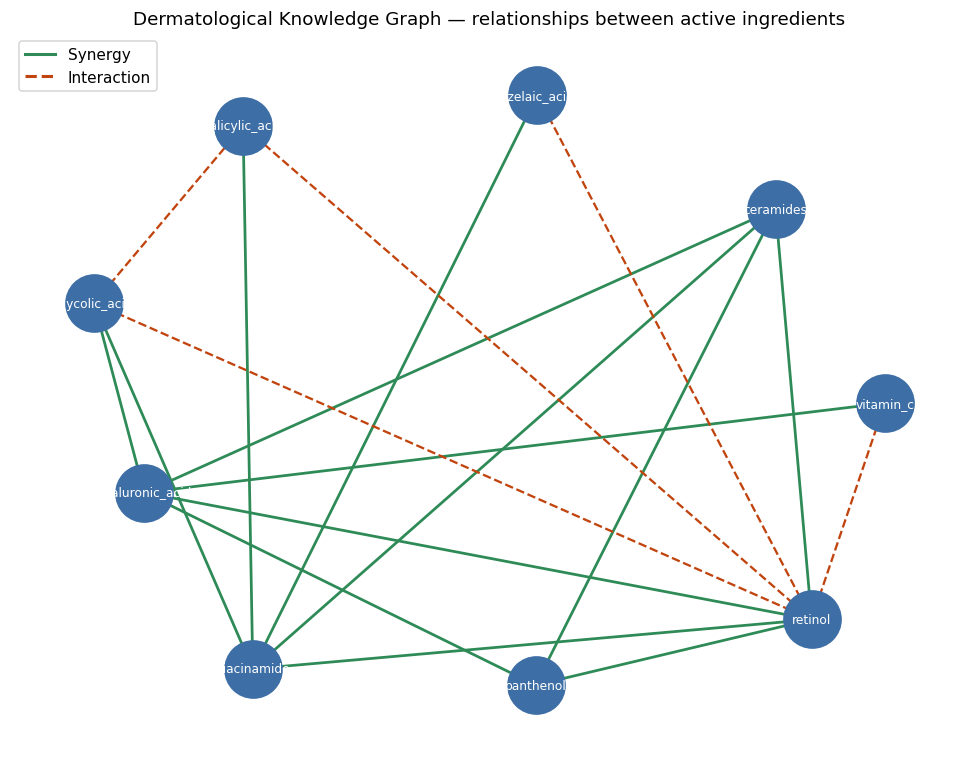

13 synergy relations, 5 interaction relations.


In [7]:
import networkx as nx
from src.recommendation.knowledge_graph import KNOWLEDGE_GRAPH, ACTIVE_INGREDIENTS

G = nx.Graph()
G.add_nodes_from(ACTIVE_INGREDIENTS)

synergy_edges, interaction_edges = set(), set()

for ingredient, relations in KNOWLEDGE_GRAPH.items():
    for other in relations["synergies"]:
        if ingredient != other:
            synergy_edges.add(tuple(sorted((ingredient, other))))
    for other in relations["interactions"]:
        interaction_edges.add(tuple(sorted((ingredient, other))))

fig, ax = plt.subplots(figsize=(9, 7))
pos = nx.spring_layout(G, seed=42, k=0.9)

nx.draw_networkx_nodes(G, pos, node_color="#3d6ea5", node_size=1400, ax=ax)
nx.draw_networkx_labels(G, pos, font_size=8, font_color="white", ax=ax)

nx.draw_networkx_edges(G, pos, edgelist=list(synergy_edges), edge_color="#2e8b57",
                        width=1.8, ax=ax, label="Synergy")
nx.draw_networkx_edges(G, pos, edgelist=list(interaction_edges), edge_color="#c1440e",
                        style="dashed", width=1.5, ax=ax, label="Interaction")

ax.set_title("Dermatological Knowledge Graph — relationships between active ingredients")
ax.legend(handles=[
    plt.Line2D([0], [0], color="#2e8b57", lw=2, label="Synergy"),
    plt.Line2D([0], [0], color="#c1440e", lw=2, ls="--", label="Interaction"),
], loc="upper left")
ax.axis("off")
plt.tight_layout()
plt.show()

print(f"{len(synergy_edges)} synergy relations, {len(interaction_edges)} interaction relations.")


## 3. Recommendation Engine Evaluation

Reproduces section **3.7**: 20 test profiles, **Precision@K** metric (a product is
relevant if it satisfies at least 2 of the 3 criteria: skin type, concern, preferred
active ingredient). Target: Precision@3 ≥ 0.70.


In [8]:
from src.recommendation.recommender import recommend_products

TEST_PROFILES = [
    {"id": "P01", "skin_type": "grasse", "concerns": ["acne"], "preferred_ingredients": ["niacinamide"], "avoid_ingredients": []},
    {"id": "P02", "skin_type": "grasse", "concerns": ["pores"], "preferred_ingredients": ["niacinamide"], "avoid_ingredients": []},
    {"id": "P03", "skin_type": "seche", "concerns": ["deshydratation"], "preferred_ingredients": ["acide_hyaluronique"], "avoid_ingredients": []},
    {"id": "P04", "skin_type": "seche", "concerns": ["secheresse"], "preferred_ingredients": ["ceramides"], "avoid_ingredients": []},
    {"id": "P05", "skin_type": "sensible", "concerns": ["rougeurs"], "preferred_ingredients": ["panthenol"], "avoid_ingredients": []},
    {"id": "P06", "skin_type": "mixte", "concerns": ["acne"], "preferred_ingredients": ["niacinamide"], "avoid_ingredients": []},
    {"id": "P07", "skin_type": "grasse", "concerns": ["taches"], "preferred_ingredients": ["vitamine_c"], "avoid_ingredients": []},
    {"id": "P08", "skin_type": "seche", "concerns": ["taches"], "preferred_ingredients": ["vitamine_c"], "avoid_ingredients": []},
    {"id": "P09", "skin_type": "sensible", "concerns": ["sensibilite"], "preferred_ingredients": ["panthenol"], "avoid_ingredients": []},
    {"id": "P10", "skin_type": "grasse", "concerns": ["rides"], "preferred_ingredients": ["niacinamide"], "avoid_ingredients": []},
    {"id": "P11", "skin_type": "seche", "concerns": ["rides"], "preferred_ingredients": ["acide_hyaluronique"], "avoid_ingredients": []},
    {"id": "P12", "skin_type": "mixte", "concerns": ["pores"], "preferred_ingredients": ["niacinamide"], "avoid_ingredients": []},
    {"id": "P13", "skin_type": "grasse", "concerns": ["deshydratation"], "preferred_ingredients": ["acide_hyaluronique"], "avoid_ingredients": []},
    {"id": "P14", "skin_type": "sensible", "concerns": ["rougeurs"], "preferred_ingredients": ["ceramides"], "avoid_ingredients": []},
    {"id": "P15", "skin_type": "seche", "concerns": ["sensibilite"], "preferred_ingredients": ["panthenol"], "avoid_ingredients": []},
    {"id": "P16", "skin_type": "grasse", "concerns": ["acne"], "preferred_ingredients": ["acide_salicylique"], "avoid_ingredients": []},
    {"id": "P17", "skin_type": "mixte", "concerns": ["taches"], "preferred_ingredients": ["vitamine_c"], "avoid_ingredients": []},
    {"id": "P18", "skin_type": "sensible", "concerns": ["rougeurs"], "preferred_ingredients": ["niacinamide"], "avoid_ingredients": []},
    {"id": "P19", "skin_type": "seche", "concerns": ["deshydratation"], "preferred_ingredients": ["acide_hyaluronique"], "avoid_ingredients": []},
    {"id": "P20", "skin_type": "grasse", "concerns": ["pores"], "preferred_ingredients": ["niacinamide"], "avoid_ingredients": []},
]

def normalize(value):
    return "" if value is None else str(value).strip().lower()

def is_relevant(product, profile):
    score = 0
    if normalize(profile.get("skin_type")) == normalize(product.get("skin_type")) and profile.get("skin_type"):
        score += 1
    text = " ".join([normalize(product.get("product_name")), normalize(product.get("category"))])
    if any(normalize(c) in text for c in profile.get("concerns", [])):
        score += 1
    ingredients = {normalize(x) for x in parse_list(product.get("active_ingredients"))}
    preferred = {normalize(x) for x in profile.get("preferred_ingredients", [])}
    if ingredients & preferred:
        score += 1
    return score >= 2

def precision_at_k(recommendations, profile, k):
    if recommendations.empty:
        return 0.0
    top_k = recommendations.head(k)
    relevant = sum(is_relevant(p, profile) for _, p in top_k.iterrows())
    return relevant / k

results = []
for profile in TEST_PROFILES:
    recs = recommend_products(profile, top_n=5)["recommendations"]
    results.append({
        "profile_id": profile["id"],
        "precision_at_3": precision_at_k(recs, profile, 3),
        "precision_at_5": precision_at_k(recs, profile, 5),
    })

eval_df = pd.DataFrame(results)
p3_mean = eval_df["precision_at_3"].mean()
p5_mean = eval_df["precision_at_5"].mean()
print(f"Mean Precision@3: {p3_mean:.3f}  (target >= 0.70 -> {'MET' if p3_mean >= 0.70 else 'NOT MET'})")
print(f"Mean Precision@5: {p5_mean:.3f}")
eval_df


Mean Precision@3: 0.717  (target >= 0.70 -> MET)
Mean Precision@5: 0.610


,profile_id,precision_at_3,precision_at_5
0,P01,1.000000,1.0
1,P02,1.000000,1.0
2,P03,0.666667,0.4
3,P04,0.000000,0.0
4,P05,1.000000,0.6
5,P06,0.666667,0.6
6,P07,0.666667,0.6
7,P08,0.666667,0.4
8,P09,1.000000,0.6
9,P10,0.666667,0.8


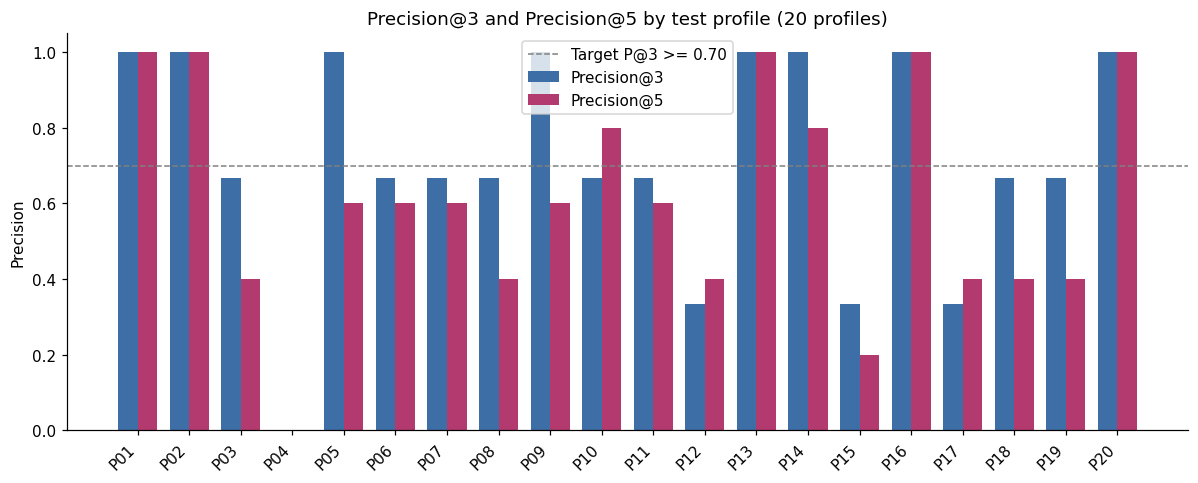

In [9]:
# --- Fig. 3.4 equivalent — Precision@3 / Precision@5 by test profile ---

fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(eval_df))
width = 0.38

ax.bar(x - width/2, eval_df["precision_at_3"], width, label="Precision@3", color="#3d6ea5")
ax.bar(x + width/2, eval_df["precision_at_5"], width, label="Precision@5", color="#b23a6e")
ax.axhline(0.70, color="gray", linestyle="--", linewidth=1, label="Target P@3 >= 0.70")

ax.set_xticks(x)
ax.set_xticklabels(eval_df["profile_id"], rotation=45, ha="right")
ax.set_ylabel("Precision")
ax.set_ylim(0, 1.05)
ax.set_title("Precision@3 and Precision@5 by test profile (20 profiles)")
ax.legend()
plt.tight_layout()
plt.show()


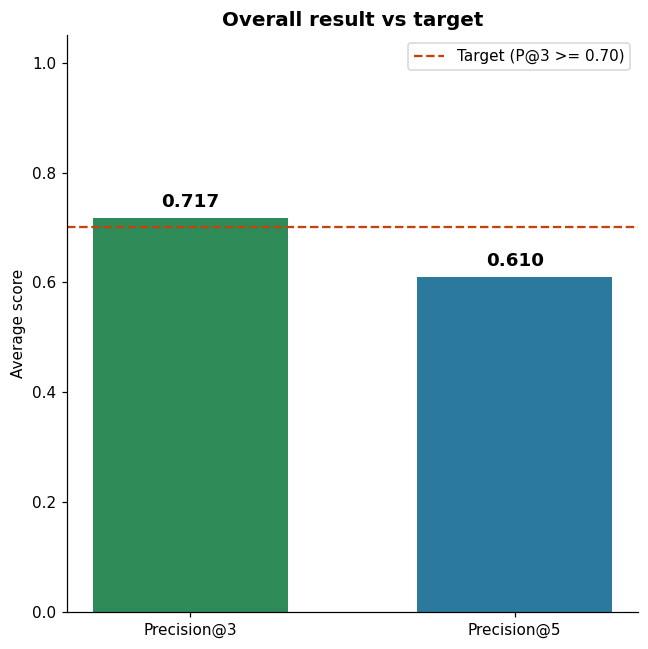

In [10]:
# --- Overall result vs target (summary view) ---

fig, ax = plt.subplots(figsize=(6, 6))
labels = ["Precision@3", "Precision@5"]
values = [p3_mean, p5_mean]
colors = ["#2e8b57", "#2b7a9e"]

bars = ax.bar(labels, values, color=colors, width=0.6)
ax.axhline(0.70, color="#c1440e", linestyle="--", linewidth=1.5,
           label="Target (P@3 >= 0.70)")

for bar, v in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.02, f"{v:.3f}",
            ha="center", fontsize=12, fontweight="bold")

ax.set_ylim(0, 1.05)
ax.set_ylabel("Average score")
ax.set_title("Overall result vs target", fontsize=13, fontweight="bold")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()


## 4. Chatbot Evaluation — Intent Classifier

Reproduces section **3.8.2**: stratified 80/20 split (`random_state=42`), TF-IDF
(bigrams) + balanced logistic regression. Target: Macro-F1 ≥ 0.80.


In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

chat_df = pd.read_csv("chatbot_dataset.csv").dropna(subset=["text", "intent"])
X, y = chat_df["text"], chat_df["intent"]


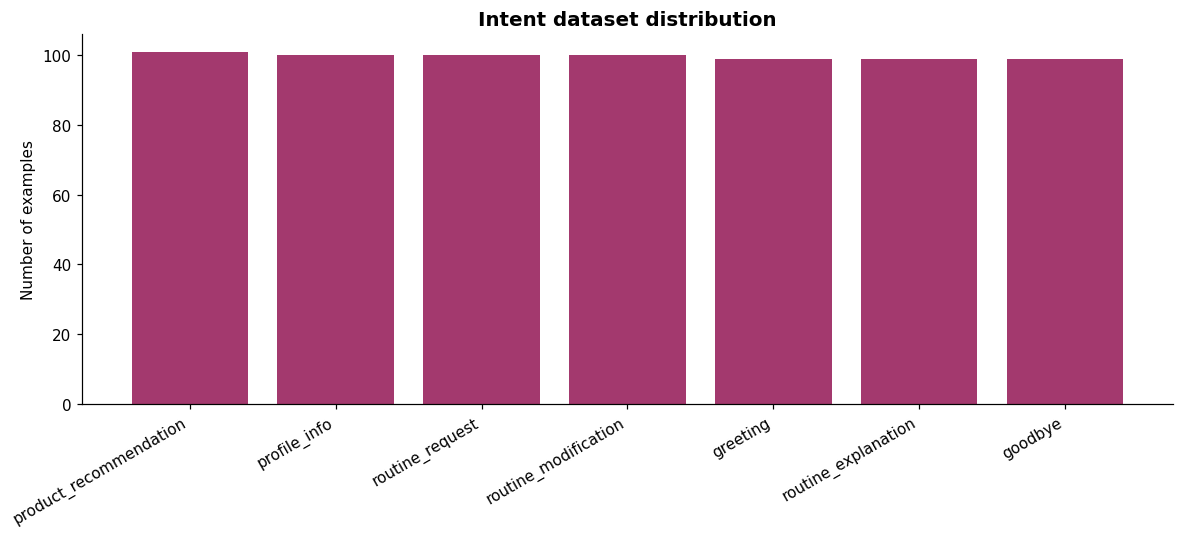

In [12]:
# --- Intent dataset distribution (class balance) ---

counts = y.value_counts()

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(counts.index, counts.values, color="#a3396e")
ax.set_ylabel("Number of examples")
ax.set_title("Intent dataset distribution", fontsize=13, fontweight="bold")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
plt.tight_layout()
plt.show()


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

intent_model = Pipeline([
    ("tfidf", TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=1,
                               max_features=5000, sublinear_tf=True)),
    ("classifier", LogisticRegression(max_iter=2000, random_state=42, class_weight="balanced")),
])
intent_model.fit(X_train, y_train)
y_pred = intent_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro")

print(f"Examples: {len(chat_df)}  |  Intents: {y.nunique()}")
print(f"Accuracy: {accuracy:.3f}")
print(f"Macro-F1: {macro_f1:.3f}  (target >= 0.80 -> {'MET' if macro_f1 >= 0.80 else 'NOT MET'})")


Examples: 698  |  Intents: 7
Accuracy: 0.971
Macro-F1: 0.971  (target >= 0.80 -> MET)


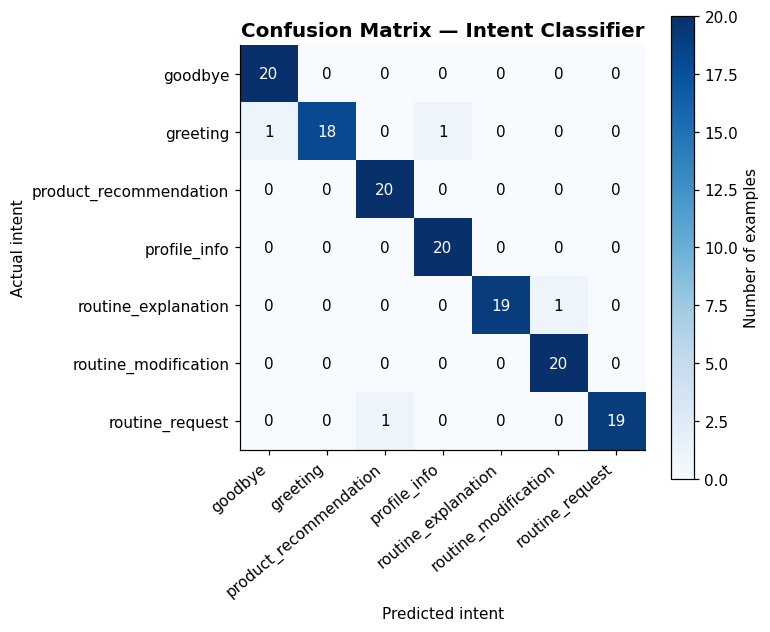

In [14]:
# --- Confusion matrix (test set) ---

labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues")
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Number of examples")

ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=40, ha="right")
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
ax.set_xlabel("Predicted intent"); ax.set_ylabel("Actual intent")
ax.set_title("Confusion Matrix — Intent Classifier", fontsize=13, fontweight="bold")

for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout()
plt.show()


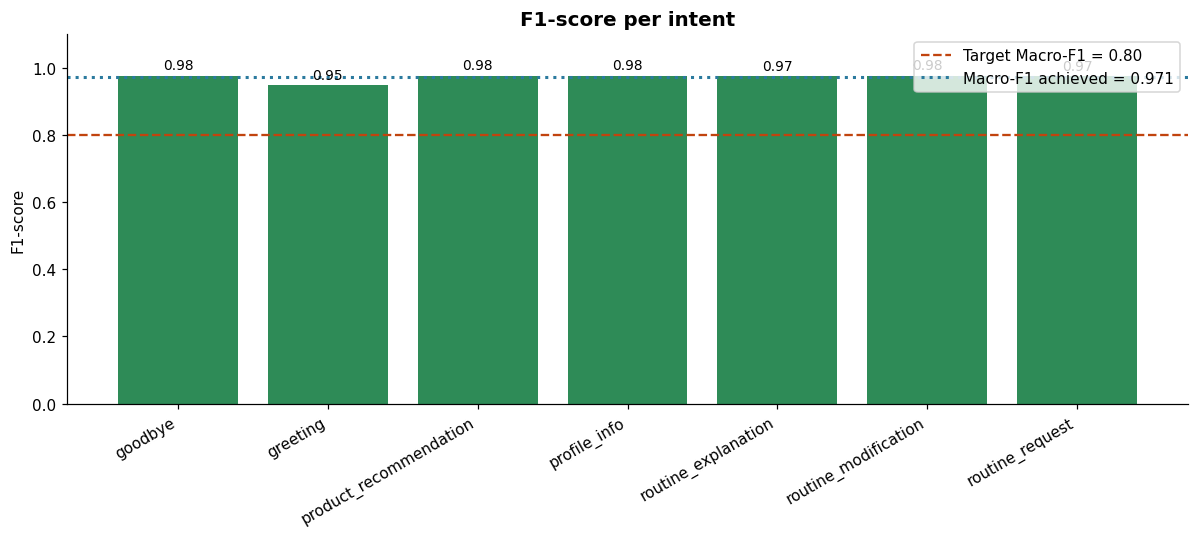

In [15]:
# --- F1-score per intent ---

from sklearn.metrics import classification_report

report = classification_report(y_test, y_pred, labels=labels, output_dict=True, zero_division=0)
f1_per_intent = pd.Series({label: report[label]["f1-score"] for label in labels})

fig, ax = plt.subplots(figsize=(11, 5))
bar_colors = ["#2e8b57" if v >= 0.80 else "#e8a33d" for v in f1_per_intent.values]
bars = ax.bar(f1_per_intent.index, f1_per_intent.values, color=bar_colors)

ax.axhline(0.80, color="#c1440e", linestyle="--", linewidth=1.5, label="Target Macro-F1 = 0.80")
ax.axhline(macro_f1, color="#2b7a9e", linestyle=":", linewidth=2, label=f"Macro-F1 achieved = {macro_f1:.3f}")

for bar, v in zip(bars, f1_per_intent.values):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.02, f"{v:.2f}", ha="center", fontsize=9)

ax.set_ylim(0, 1.1)
ax.set_ylabel("F1-score")
ax.set_title("F1-score per intent", fontsize=13, fontweight="bold")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()


## 5. Summary of Metrics Against Targets


In [16]:
summary = pd.DataFrame([
    ["Precision@3 (recommendation engine)", "≥ 0.70", f"{p3_mean:.3f}", "Met" if p3_mean >= 0.70 else "Not met"],
    ["Macro-F1 (intent classifier)", "≥ 0.80", f"{macro_f1:.3f}", "Met" if macro_f1 >= 0.80 else "Not met"],
], columns=["Metric", "Target", "Result", "Status"])

summary


,Metric,Target,Result,Status
0,Precision@3 (recommendation engine),≥ 0.70,0.717,Met
1,Macro-F1 (intent classifier),≥ 0.80,0.971,Met
